# 05 - Avaliação, calibração, estabilidade, explicabilidade e viés

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 200, 'display.max_columns', 50)


{'auc': 0.7272352989506549, 'auc_ic95': (np.float64(0.7189402109437594), np.float64(0.7367705792391372)), 'gini': 0.4544705979013097, 'ks': 0.33846013183701756, 'brier': 0.09682792687028946, 'taxa': 0.12258540946014225, 'n_clientes_novos': 7955, 'auc_clientes_novos': 0.6181929091266718, 'auc_com_historico': 0.7334612797832766}
          n  prob_media  taxa_real   lift
decil                                    
1      2573       0.023      0.030  0.247
2      2573       0.038      0.048  0.390
3      2573       0.048      0.054  0.441
4      2573       0.058      0.071  0.580
5      2573       0.069      0.075  0.609
6      2572       0.083      0.098  0.796
7      2573       0.102      0.131  1.065
8      2573       0.128      0.163  1.332
9      2573       0.175      0.171  1.392
10     2573       0.402      0.386  3.148


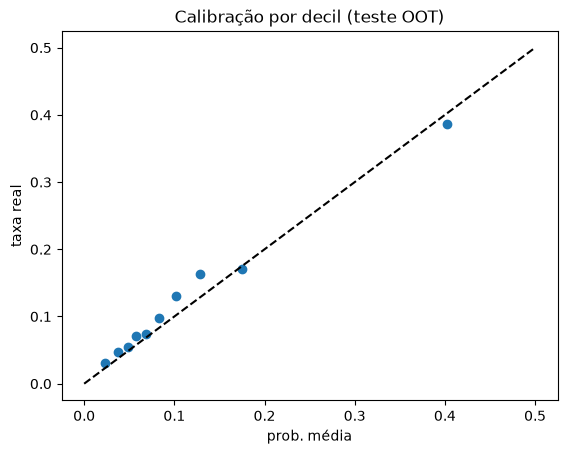

In [2]:
from src.train import *
from src.config import OUT
from src.evaluate import decis, psi
FIG = OUT / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
m, cats, r, (X, y, tr, va, te, p) = rodar()
print(r)
t = decis(y[te], p); print(t.round(3))
plt.plot([0,.5],[0,.5],'k--'); plt.scatter(t.prob_media, t.taxa_real); plt.xlabel('prob. média'); plt.ylabel('taxa real'); plt.title('Calibração por decil (teste OOT)'); plt.savefig(FIG/'calibration.png', dpi=130, bbox_inches='tight'); plt.show()

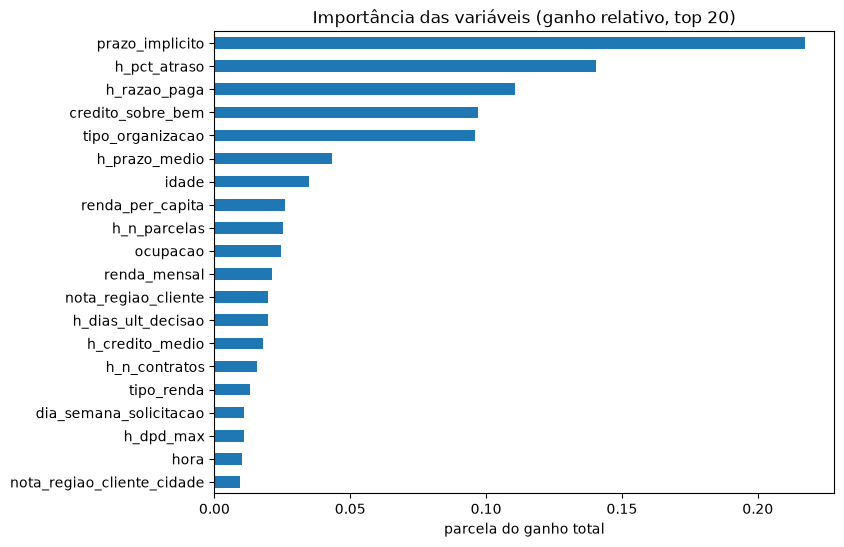

prazo_implicito               0.2173
h_pct_atraso                  0.1404
h_razao_paga                  0.1105
credito_sobre_bem             0.0969
tipo_organizacao              0.0960
h_prazo_medio                 0.0432
idade                         0.0350
renda_per_capita              0.0262
h_n_parcelas                  0.0254
ocupacao                      0.0245
renda_mensal                  0.0211
nota_regiao_cliente           0.0197
h_dias_ult_decisao            0.0196
h_credito_medio               0.0177
h_n_contratos                 0.0157
tipo_renda                    0.0130
dia_semana_solicitacao        0.0109
h_dpd_max                     0.0108
hora                          0.0100
nota_regiao_cliente_cidade    0.0096
qtd_membros_familia           0.0063
h_dpd_medio                   0.0061
estado_civil                  0.0044
tipo_contrato                 0.0034
qtd_filhos                    0.0029
h_pct_atraso30                0.0023
nivel_educacao                0.0022
s

In [3]:
# importância das variáveis (ganho do LightGBM)
imp = pd.Series(m.booster_.feature_importance('gain'), X.columns).sort_values(ascending=False)
imp = (imp / imp.sum()).rename('ganho_relativo'); imp.to_csv(OUT/'feature_importance.csv')
imp.head(20)[::-1].plot.barh(figsize=(8, 6), title='Importância das variáveis (ganho relativo, top 20)'); plt.xlabel('parcela do ganho total'); plt.savefig(FIG/'feature_importance.png', dpi=130, bbox_inches='tight'); plt.show()
print(imp.round(4).to_string())

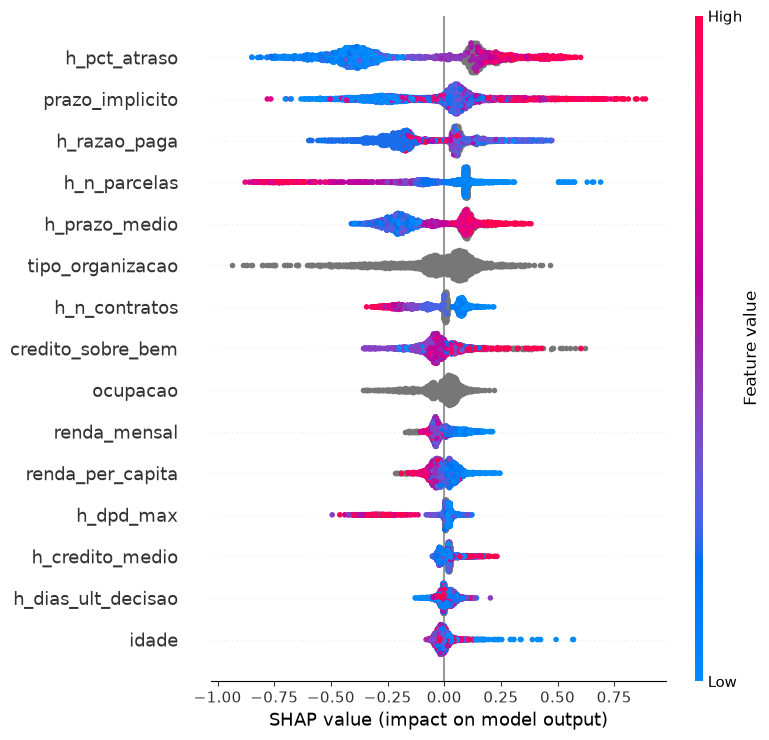

In [4]:
import shap
Xs = X[te].sample(3000, random_state=42)
sv = shap.TreeExplainer(m).shap_values(Xs)
shap.summary_plot(sv[1] if isinstance(sv, list) else sv, Xs, max_display=15, show=False); plt.savefig(FIG/'shap_summary.png', dpi=130, bbox_inches='tight'); plt.show()

In [5]:
# ablação: sexo/idade e histórico
for nome, ex in {'sem sexo/idade': ['sexo','idade'], 'sem histórico': [c for c in X.columns if c.startswith('h_') or c == 'tem_historico']}.items():
    rr = rodar(excluir=ex)[2]; print(nome, 'AUC', round(rr['auc'],4), 'KS', round(rr['ks'],4), '| completo AUC', round(r['auc'],4), 'KS', round(r['ks'],4))

sem sexo/idade AUC 0.7281 KS 0.3366 | completo AUC 0.7272 KS 0.3385


sem histórico AUC 0.6341 KS 0.2341 | completo AUC 0.7272 KS 0.3385


In [6]:
# viés por segmento (teste OOT)
from sklearn.metrics import roc_auc_score
from src.policy import decisao
d = X[te].assign(y=y[te], p=p, ok=(decisao(p) == 'aprovar'))
d['faixa_idade'] = pd.cut(d.idade, [0,30,40,50,60,120])
for col in ['sexo','faixa_idade']:
    print(d.groupby(col, observed=True).apply(lambda g: pd.Series({'n': len(g), 'auc': roc_auc_score(g.y, g.p) if g.y.nunique()>1 else np.nan, 'taxa_real': g.y.mean(), 'prob_media': g.p.mean(), 'aprov_auto': g.ok.mean()})).round(3))

                     n    auc  taxa_real  prob_media  aprov_auto
sexo                                                            
feminino       16917.0  0.730      0.120       0.112       0.642
masculino       8786.0  0.722      0.126       0.115       0.638
nao informado     26.0  0.684      0.269       0.120       0.615
                  n    auc  taxa_real  prob_media  aprov_auto
faixa_idade                                                  
(0, 30]      5179.0  0.713      0.131       0.125       0.572
(30, 40]     6898.0  0.726      0.111       0.105       0.662
(40, 50]     5726.0  0.734      0.122       0.108       0.667
(50, 60]     5405.0  0.720      0.128       0.113       0.639
(60, 120]    2448.0  0.758      0.123       0.116       0.673


In [7]:
sub = pd.read_csv('../submissao/submission_predictions.csv')
print('PSI score teste x submissão:', round(psi(p, sub.prob_inadimplencia.values), 3), '(>0.25 = mudança forte)')

PSI score teste x submissão: 0.185 (>0.25 = mudança forte)
